In [4]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Ditya Gupta\OneDrive\Desktop\Telegram_bot\virtual_env\Scripts\python.exe -m pip install --upgrade pip


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries installed successfully!")

All libraries installed successfully!


In [5]:

import os
import pandas as pd

print("Current folder:", os.getcwd())

df = pd.read_csv(
    r"C:\Users\Ditya Gupta\OneDrive\Desktop\AI-Diabetes-Prediction\datasets\diabetes_binary_health_indicators_BRFSS2015.csv"
)

print("Dataset loaded successfully!")

df.head()

Current folder: C:\Users\Ditya Gupta\OneDrive\Desktop\project images\Python
Dataset loaded successfully!


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [6]:

# Check the number of rows and columns

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 253680
Total Columns: 22


In [7]:

# Display all column names
print("Dataset Columns:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

Dataset Columns:
['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Frui

# Data Quality Check

In [8]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Check duplicate records
print("\nTotal Duplicate Records:")
print(df.duplicated().sum())

Missing Values:
Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

Total Missing Values:
0

Total Duplicate Records:
24206


# Diabetes Class Distribution

In [9]:
# Count diabetic and non-diabetic records
print("Diabetes Class Distribution:")
print(df['Diabetes_binary'].value_counts())

# Calculate percentage distribution
print("\nPercentage Distribution:")
print(df['Diabetes_binary'].value_counts(normalize=True) * 100)

Diabetes Class Distribution:
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

Percentage Distribution:
Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64


# Visualize the distribution

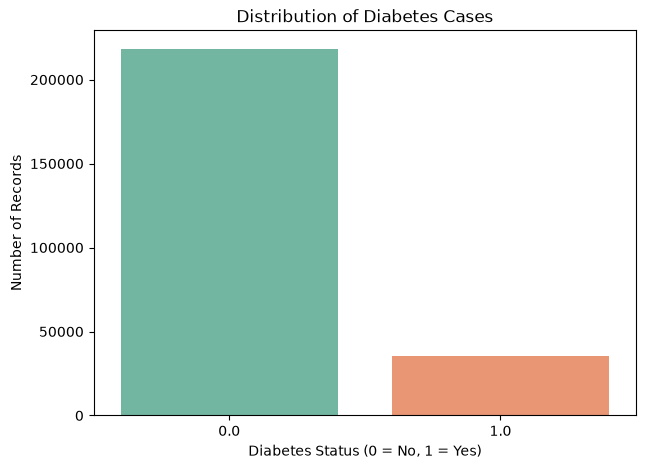

In [10]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Diabetes_binary',
    hue='Diabetes_binary',
    palette='Set2',
    legend=False
)

plt.title("Distribution of Diabetes Cases")
plt.xlabel("Diabetes Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.show()

#### What have we learned?
#### Our dataset is imbalanced because non-diabetic records substantially outnumber diabetic records.
#### This means that when we train the Random Forest model, we'll need to evaluate recall, precision, F1-score, and ROC-AUC, not just accuracy.

# Exploratory Data Analysis (EDA)

## 1. BMI Distribution by Diabetes Status

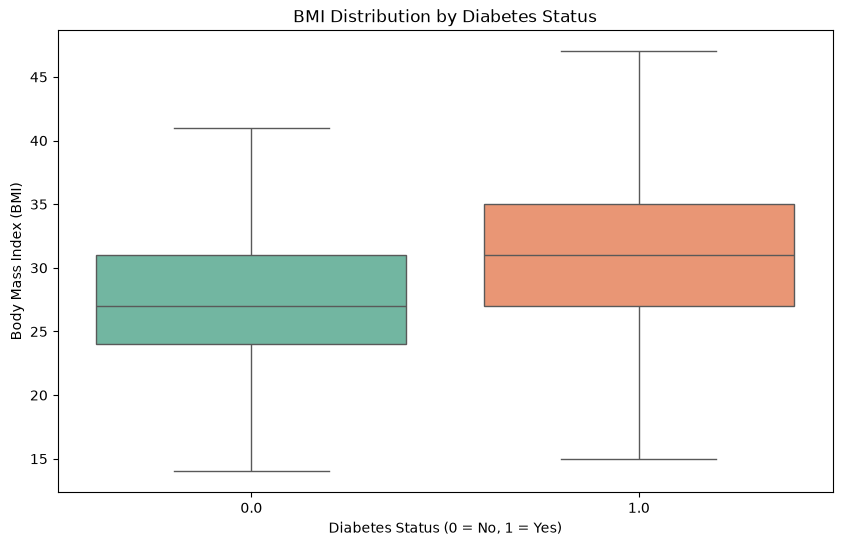

In [11]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Diabetes_binary',
    y='BMI',
    hue='Diabetes_binary',
    palette='Set2',
    legend=False,
    showfliers=False
)

plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes Status (0 = No, 1 = Yes)")
plt.ylabel("Body Mass Index (BMI)")

plt.show()

##### The graph will help us compare:
##### - The median BMI of both groups.
##### - The spread of BMI values.
##### - Whether respondents with diabetes tend to have different BMI distributions.
##### Remember, this shows an association, not proof that BMI causes diabetes.
    
##### Why are we doing this?
##### It specifically requires visualizing relationships between health factors and diabetes.
##### These visualizations will help us prepare the analysis section of my final report.

## 2. Age Category vs Diabetes Status

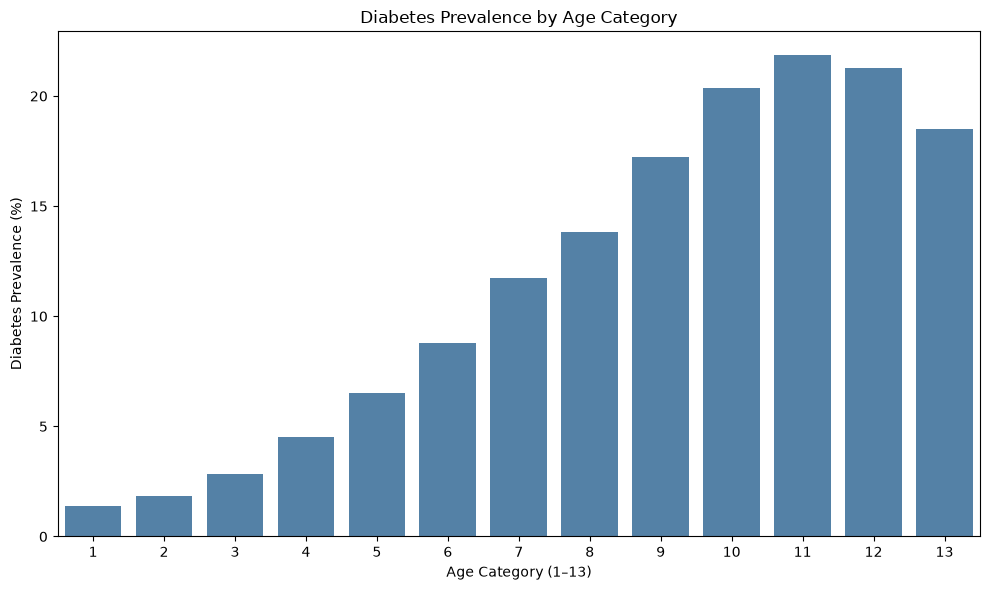

In [12]:
# Calculate diabetes percentage for each age category

age_diabetes = (
    df.groupby('Age')['Diabetes_binary']
    .mean() * 100
)

# Create visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    x=age_diabetes.index,
    y=age_diabetes.values,
    color='steelblue'
)

plt.title("Diabetes Prevalence by Age Category")
plt.xlabel("Age Category (1–13)")
plt.ylabel("Diabetes Prevalence (%)")

plt.xticks(range(13), range(1, 14))
plt.tight_layout()
plt.show()

##### What does this graph tell us?
##### - The X-axis represents 13 age categories.
##### - The Y-axis represents the percentage of respondents classified as diabetic within each category.
##### - We can identify which age categories have higher or lower diabetes prevalence.
##### Important: A higher prevalence in an age category does not establish that age alone causes diabetes.

## 3. High Blood Pressure vs Diabetes

Diabetes Prevalence by Blood Pressure:
HighBP
0.0     6.035167
1.0    24.445690
Name: Diabetes_binary, dtype: float64


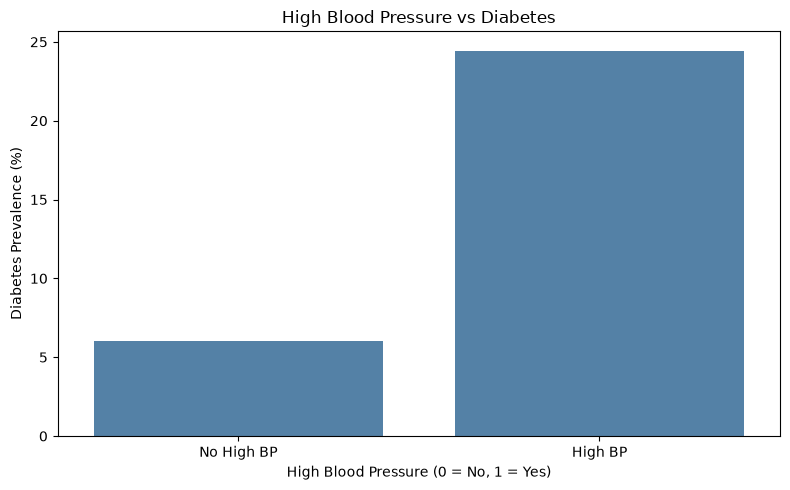

In [13]:
# Calculate diabetes prevalence by blood pressure status

bp_diabetes = (
    df.groupby('HighBP')['Diabetes_binary']
    .mean() * 100
)

print("Diabetes Prevalence by Blood Pressure:")
print(bp_diabetes)

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=bp_diabetes.index,
    y=bp_diabetes.values,
    color='steelblue'
)

plt.title("High Blood Pressure vs Diabetes")
plt.xlabel("High Blood Pressure (0 = No, 1 = Yes)")
plt.ylabel("Diabetes Prevalence (%)")

plt.xticks([0, 1], ["No High BP", "High BP"])
plt.tight_layout()
plt.show()

##### What will the graph show?
##### The graph will compare diabetes prevalence between respondents who reported high blood pressure and those who did not.

## 4. High Cholesterol vs Diabetes

Diabetes Prevalence by Cholesterol Status:
HighChol
0.0     7.981436
1.0    22.014853
Name: Diabetes_binary, dtype: float64


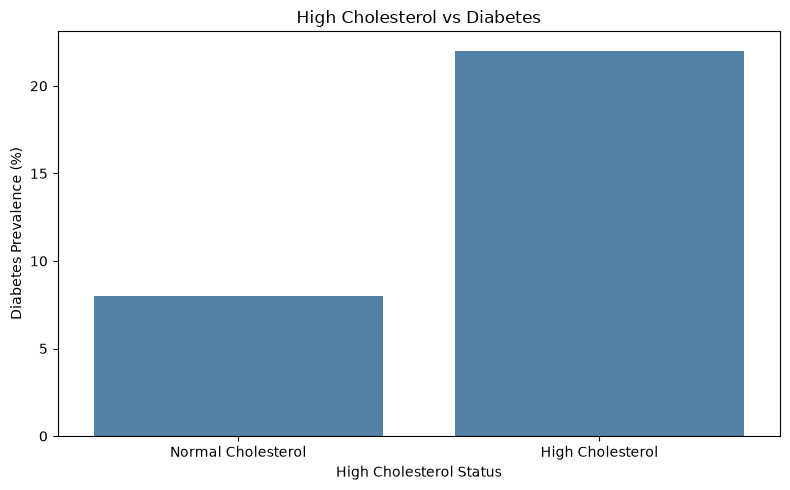

In [14]:
# Calculate diabetes prevalence by cholesterol status

chol_diabetes = (
    df.groupby('HighChol')['Diabetes_binary']
    .mean() * 100
)

print("Diabetes Prevalence by Cholesterol Status:")
print(chol_diabetes)

# Create visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=chol_diabetes.index,
    y=chol_diabetes.values,
    color='steelblue'
)

plt.title("High Cholesterol vs Diabetes")
plt.xlabel("High Cholesterol Status")
plt.ylabel("Diabetes Prevalence (%)")

plt.xticks([0, 1], ["Normal Cholesterol", "High Cholesterol"])

plt.tight_layout()
plt.show()

##### What does this graph tell us?
##### This graph compares diabetes prevalence between respondents with and without high cholesterol.
##### If the high-cholesterol group has a higher percentage, it suggests an association between high cholesterol and diabetes in this dataset.
##### It does not prove causation.

## 5. Correlation Heatmap

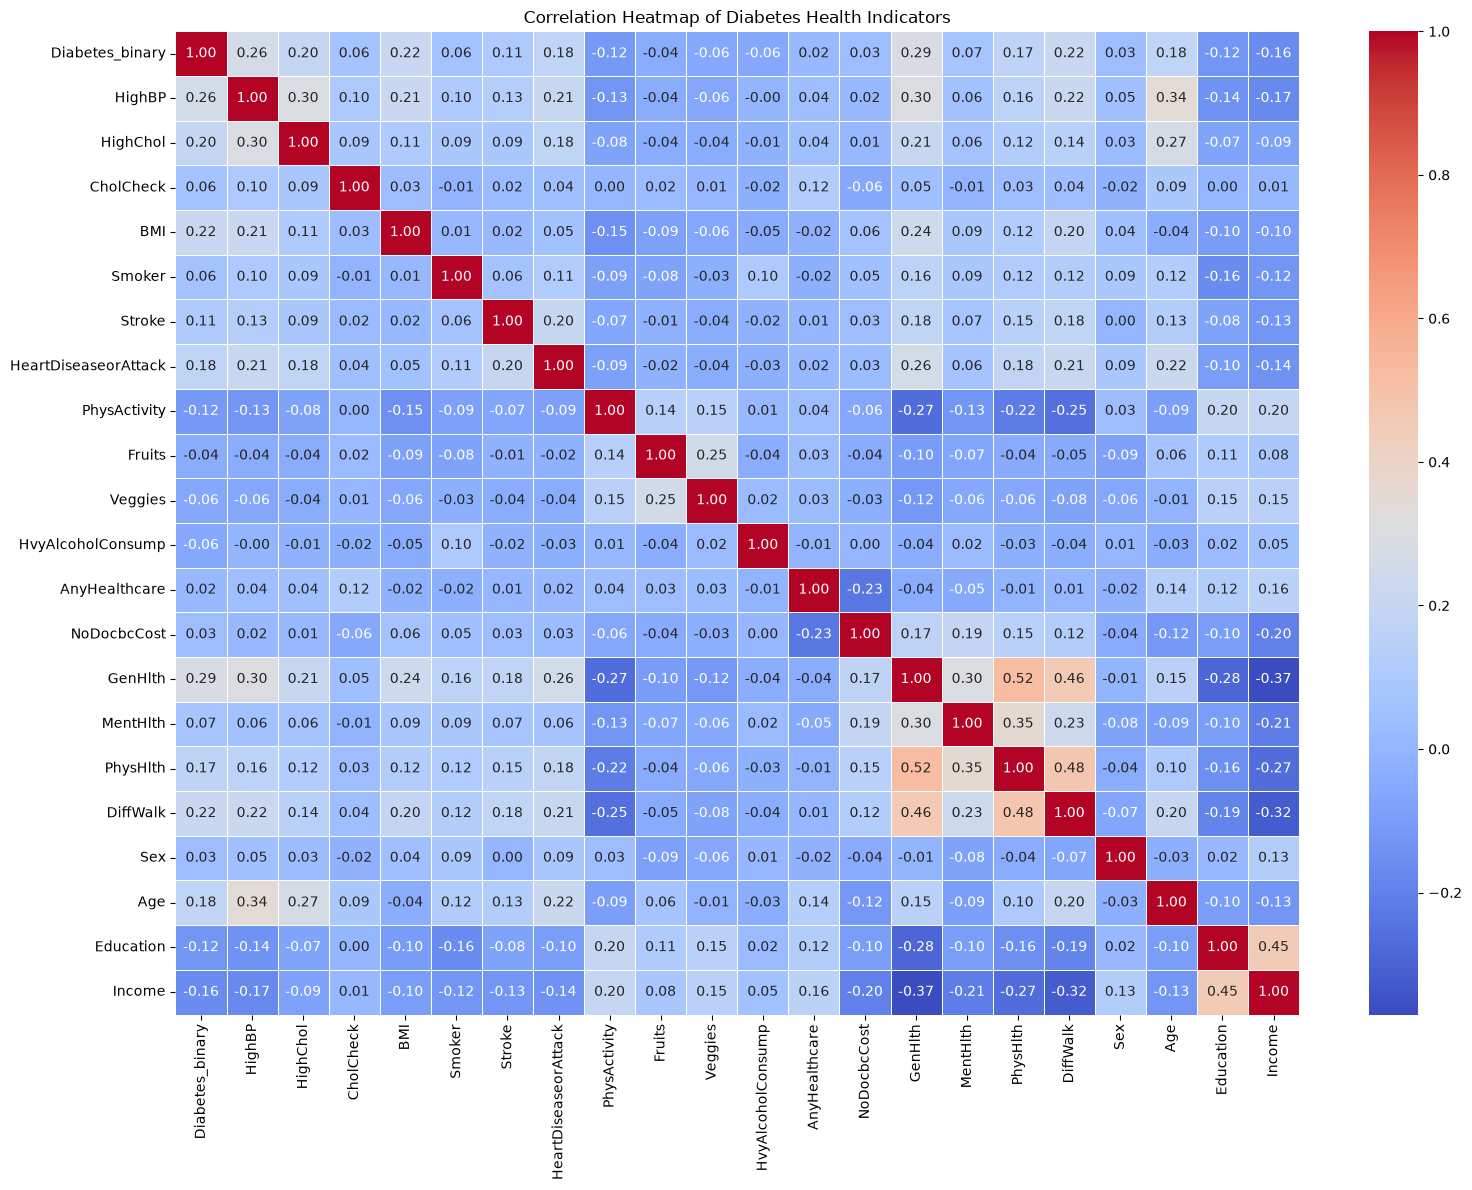

In [15]:
# Calculate correlation matrix
correlation_matrix = df.corr()

# Create correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Diabetes Health Indicators")
plt.tight_layout()
plt.show()

In [ ]:
 How to interpret the heatmap
 | Correlation value|      Meaning                    |
 - - - - - - - -  - - - - - - - - - - - - - - - - - - -
 | +1.0	            |  Perfect positive correlation   |
 | +0.5	            |  Moderate positive correlation  |
 | 0.0	            |  No linear correlation          |
 | -0.5	            |  Moderate negative correlation  |
 | -1.0	            |  Perfect negative correlation   |

 For example, if BMI and Diabetes_binary have a positive correlation, higher BMI values tend to be associated with diabetes classification
 1 in the dataset. This does not establish causation.

### Find the features most correlated with diabetes

In [ ]:
# Correlation of each feature with diabetes

diabetes_corr = (
    correlation_matrix['Diabetes_binary']
    .drop('Diabetes_binary')
    .sort_values(ascending=False)
)

print("Feature Correlation with Diabetes:")
print(diabetes_corr)

## Machine learning Aspects

## I. Feature Selection and Target Separation

In [17]:
# Separate features and target variable

X = df.drop('Diabetes_binary', axis=1)

y = df['Diabetes_binary']

# Display feature and target shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Display all selected features
print("\nSelected Features:")
print(X.columns.tolist())

# Display target distribution
print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (253680, 21)
Target Shape: (253680,)

Selected Features:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Target Distribution:
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64


##### Why is this step important?
##### The Random Forest model will learn relationships between the health indicators in X and the known classifications in y.

## II. Split the Dataset into Training and Testing Data

In [18]:
# Import train-test split function
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display shapes
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (202944, 21)
X_test Shape: (50736, 21)
y_train Shape: (202944,)
y_test Shape: (50736,)


In [ ]:
Understanding the code
Parameter	            Meaning
test_size=0.20	    Reserves 20% of the data for testing
random_state=42	    Makes the random split reproducible
stratify=y	        Maintains approximately the same diabetes class proportions in both sets
X_train, y_train	Data used for training
X_test, y_test	    Unseen data used for final evaluation

Important: We won't train or fit preprocessing steps on the testing data. This helps prevent data leakage and gives us a more reliable evaluation.

## III. Data Preprocessing

### Handle Missing Values

In [21]:

from sklearn.impute import SimpleImputer

# Check missing values in training and testing data
print("Missing values in training data:")
print(X_train.isnull().sum().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum().sum())

# Create an imputer
imputer = SimpleImputer(strategy='median')

# Fit only on training data
X_train_processed = imputer.fit_transform(X_train)

# Apply the same transformation to testing data
X_test_processed = imputer.transform(X_test)

print("\nPreprocessing completed successfully!")
print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

Missing values in training data:
0

Missing values in testing data:
0

Preprocessing completed successfully!
Training Data Shape: (202944, 21)
Testing Data Shape: (50736, 21)


## IV. Random Forest Model Training

In [22]:

# Import Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train the model
print("Training Random Forest Model...")

rf_model.fit(X_train_processed, y_train)

print("Random Forest Model Trained Successfully!")

Training Random Forest Model...
Random Forest Model Trained Successfully!


In [ ]:
What does this code do?
Parameter	                         Explanation
n_estimators=100	        Creates 100 decision trees
max_depth=15	            Limits tree depth to help control overfitting
class_weight='balanced'	    Gives more weight to the minority diabetes class
random_state=42         	Makes results reproducible
n_jobs=-1	                Uses available CPU cores for faster training
.fit()	                    Trains the model using the training dataset

## V. Model Evaluation and Performance Analysis

### 1. Evaluate the Random Forest Model

In [23]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict using testing data
y_pred = rf_model.predict(X_test_processed)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Display results
print("Random Forest Model Evaluation")
print("--------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Random Forest Model Evaluation
--------------------------------
Accuracy:  0.7554
Precision: 0.3277
Recall:    0.7185
F1-Score:  0.4501

Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      0.76      0.84     43667
         1.0       0.33      0.72      0.45      7069

    accuracy                           0.76     50736
   macro avg       0.64      0.74      0.65     50736
weighted avg       0.86      0.76      0.79     50736



In [ ]:
Understanding the evaluation metrics
Metric	Meaning
Accuracy	Percentage of all predictions that are correct
Precision	Of the people predicted as diabetic, how many actually have the diabetes label
Recall	Of the people labelled diabetic, how many the model correctly identifies
F1-score	Balances precision and recall

Because your dataset has more non-diabetic than diabetic records, recall and F1-score are particularly important alongside accuracy.

### 2. Visualize Model Performance

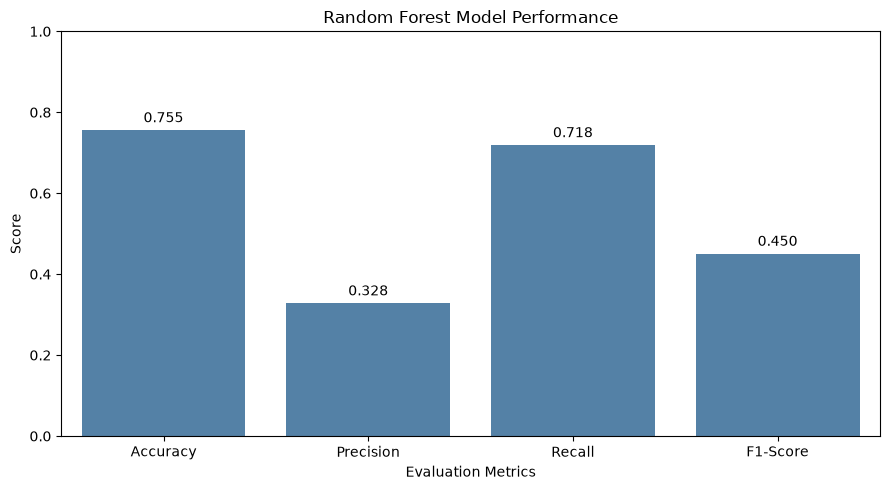

In [24]:

# Store evaluation metrics
metrics = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1
}

plt.figure(figsize=(9, 5))

sns.barplot(
    x=list(metrics.keys()),
    y=list(metrics.values()),
    color='steelblue'
)

plt.title("Random Forest Model Performance")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)

for i, value in enumerate(metrics.values()):
    plt.text(i, value + 0.02, f"{value:.3f}", ha='center')

plt.tight_layout()
plt.show()

### 3. Confusion Matrix

Confusion Matrix:
[[33246 10421]
 [ 1990  5079]]


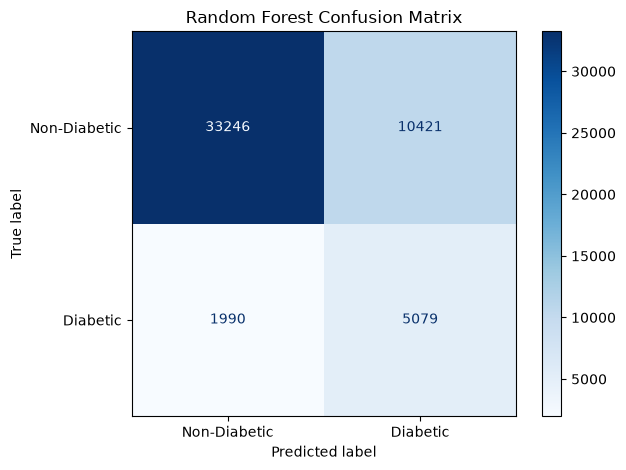

In [25]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Diabetic", "Diabetic"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
What does each result mean?
      Term	                       Meaning
True Negative (TN)	     Correctly predicts non-diabetic
False Positive (FP)	     Predicts diabetic when the label is non-diabetic
False Negative (FN)	     Predicts non-diabetic when the label is diabetic
True Positive (TP)	     Correctly predicts diabetic

For this project, false negatives are particularly important to examine because they represent diabetes-labelled cases that the model misses.

### 4. ROC-AUC Curve

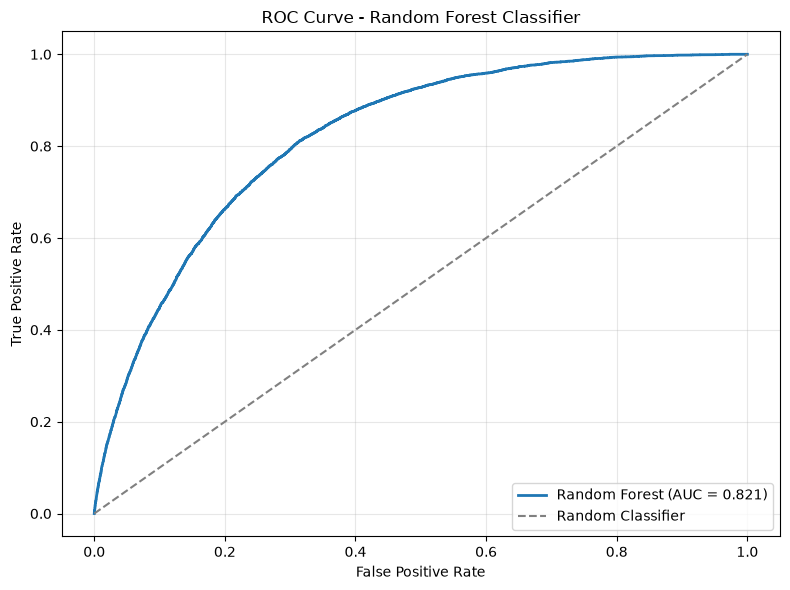

ROC-AUC Score: 0.8214


In [26]:

from sklearn.metrics import roc_curve, roc_auc_score

# Get predicted probabilities for class 1
y_prob = rf_model.predict_proba(X_test_processed)[:, 1]

# Calculate ROC-AUC score
roc_auc = roc_auc_score(y_test, y_prob)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest Classifier")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")

In [ ]:
What is ROC-AUC?
- ROC curve: Shows how the true positive rate changes against the false positive rate at different classification thresholds.
- AUC: Measures how well the model distinguishes between the two classes.
- An AUC of 0.5 indicates random-level discrimination; 1.0 indicates perfect discrimination on the evaluated data.
A high ROC-AUC alone does not mean a model is medically reliable or that its predicted probabilities are calibrated.

## 6. Saving the Trained Random Forest Model

In [27]:
import joblib
import os

# Create models folder
os.makedirs("models", exist_ok=True)

# Save trained Random Forest model
joblib.dump(rf_model, "models/random_forest_model.pkl")

# Save preprocessing imputer
joblib.dump(imputer, "models/imputer.pkl")

# Save feature names
joblib.dump(X.columns.tolist(), "models/feature_names.pkl")

print("Model and preprocessing files saved successfully!")

Model and preprocessing files saved successfully!


In [28]:
import os

print("Saved Model Files:")

for file in os.listdir("models"):
    print(file)

Saved Model Files:
feature_names.pkl
imputer.pkl
random_forest_model.pkl


## 7. Test Loading the Saved Model

In [29]:

# Load saved model and preprocessing objects

loaded_model = joblib.load("models/random_forest_model.pkl")
loaded_imputer = joblib.load("models/imputer.pkl")
loaded_features = joblib.load("models/feature_names.pkl")

# Make a prediction on the first test record
sample = X_test[loaded_features].iloc[[0]]

sample_processed = loaded_imputer.transform(sample)

prediction = loaded_model.predict(sample_processed)[0]
probability = loaded_model.predict_proba(sample_processed)[0, 1]

print("Predicted Class:", prediction)
print(f"Predicted Probability: {probability:.2%}")

Predicted Class: 1.0
Predicted Probability: 54.80%


## VI. Building the Streamlit Web Application

In [30]:
%pip install streamlit

  Using cached streamlit-1.66.1-py3-none-any.whl.metadata (10 kB)
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached pyarrow-26.0.0-cp313-cp313-win_amd64.whl.metadata (3.0 kB)
  Using cached starlette-1.9.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached python_multipart-0.0.32-py3-none-any.whl.metadata (2.1 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached watchdog-6.0.0-py3-none-win_amd64.whl.metadata (44 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached markupsafe-3.0.4-cp313-cp313-win_amd64.whl.metadata (2.8 kB)
  Using cached attrs-26.1.0-py3-none-any.


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Ditya Gupta\OneDrive\Desktop\Telegram_bot\virtual_env\Scripts\python.exe -m pip install --upgrade pip


In [31]:
import streamlit as st

print("Streamlit installed successfully!")
print("Streamlit Version:", st.__version__)

Streamlit installed successfully!
Streamlit Version: 1.66.1


In [32]:
import os

# Check current working directory
print("Current Folder:", os.getcwd())

# Check saved model files
print("\nModel Files:")
print(os.listdir("models"))

Current Folder: C:\Users\Ditya Gupta\OneDrive\Desktop\project images\Python

Model Files:
['feature_names.pkl', 'imputer.pkl', 'random_forest_model.pkl']


In [33]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="AI Diabetes Prediction",
    page_icon="🩺",
    layout="centered"
)

@st.cache_resource
def load_resources():
    model = joblib.load("models/random_forest_model.pkl")
    imputer = joblib.load("models/imputer.pkl")
    features = joblib.load("models/feature_names.pkl")
    return model, imputer, features

model, imputer, features = load_resources()

st.title("🩺 AI-Based Diabetes Prediction System")
st.write("Enter health information to generate a machine learning prediction.")

st.info(
    "Educational project only. This model cannot diagnose "
    "or rule out diabetes."
)

# Input fields
with st.form("prediction_form"):

    st.subheader("Patient Health Information")

    user_inputs = {}

    for feature in features:
        if feature == "BMI":
            user_inputs[feature] = st.number_input(
                "BMI",
                min_value=10.0,
                max_value=100.0,
                value=25.0
            )

        elif feature == "Age":
            user_inputs[feature] = st.selectbox(
                "Age Category (1–13)",
                options=list(range(1, 14)),
                index=6
            )

        elif feature in ["GenHlth", "MentHlth", "PhysHlth",
                         "Education", "Income"]:
            limits = {
                "GenHlth": (1, 5),
                "MentHlth": (0, 30),
                "PhysHlth": (0, 30),
                "Education": (1, 6),
                "Income": (1, 8)
            }

            low, high = limits[feature]

            user_inputs[feature] = st.number_input(
                feature,
                min_value=low,
                max_value=high,
                value=low
            )

        else:
            user_inputs[feature] = st.selectbox(
                feature,
                options=[0, 1],
                format_func=lambda x: "Yes" if x == 1 else "No"
            )

    submitted = st.form_submit_button(
        "Predict Diabetes Classification",
        use_container_width=True
    )

if submitted:

    input_df = pd.DataFrame([user_inputs])
    input_df = input_df[features]

    processed_input = imputer.transform(input_df)

    prediction = model.predict(processed_input)[0]
    probability = model.predict_proba(processed_input)[0][1]

    st.subheader("Prediction Result")

    if prediction == 1:
        st.warning("Predicted Class: Diabetes (1)")
    else:
        st.success("Predicted Class: Non-Diabetes (0)")

    st.metric(
        "Model Estimated Probability for Class 1",
        f"{probability * 100:.2f}%"
    )

    st.caption(
        "This probability is not a clinically validated risk score. "
        "Consult a qualified healthcare professional for diagnosis."
    )

Writing app.py


In [34]:
import os
print(os.getcwd())

C:\Users\Ditya Gupta\OneDrive\Desktop\project images\Python


In [35]:
import shutil

shutil.copy("app.py", "app_backup.py")

print("Application backup created successfully!")

Application backup created successfully!


### Improving Your Streamlit Application Interface

### Improve the input labels

In [36]:
# Read the existing Streamlit application
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text(encoding="utf-8")

# Create readable labels for the features
labels = {
    "HighBP": "High Blood Pressure",
    "HighChol": "High Cholesterol",
    "CholCheck": "Cholesterol Checked in Past 5 Years",
    "BMI": "Body Mass Index (BMI)",
    "Smoker": "Smoked at Least 100 Cigarettes in Lifetime",
    "Stroke": "History of Stroke",
    "HeartDiseaseorAttack": "Heart Disease or Heart Attack",
    "PhysActivity": "Physical Activity in Past 30 Days",
    "Fruits": "Consumes Fruit Daily",
    "Veggies": "Consumes Vegetables Daily",
    "HvyAlcoholConsump": "Heavy Alcohol Consumption Indicator",
    "AnyHealthcare": "Has Healthcare Coverage",
    "NoDocbcCost": "Could Not See Doctor Due to Cost",
    "GenHlth": "General Health Rating",
    "MentHlth": "Poor Mental Health Days (Past 30 Days)",
    "PhysHlth": "Poor Physical Health Days (Past 30 Days)",
    "DiffWalk": "Difficulty Walking or Climbing Stairs",
    "Sex": "Sex",
    "Age": "Age Group",
    "Education": "Education Level",
    "Income": "Income Category"
}

# Replace only the labels displayed in the app
app_code = app_code.replace(
    'user_inputs[feature] = st.selectbox(\n                feature,',
    'user_inputs[feature] = st.selectbox(\n                labels.get(feature, feature),'
)

app_code = app_code.replace(
    'user_inputs[feature] = st.number_input(\n                feature,',
    'user_inputs[feature] = st.number_input(\n                labels.get(feature, feature),'
)

# Insert label dictionary into app.py
insert_point = '# Input fields'
label_code = "labels = " + repr(labels) + "\n\n"

if "labels = {" not in app_code:
    app_code = app_code.replace(
        insert_point,
        label_code + insert_point
    )

app_path.write_text(app_code, encoding="utf-8")

print("Feature labels updated successfully!")

Feature labels updated successfully!


### Correct the Sex field

In [37]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text(encoding="utf-8")

old_code = '''        else:
            user_inputs[feature] = st.selectbox(
                labels.get(feature, feature),
                options=[0, 1],
                format_func=lambda x: "Yes" if x == 1 else "No"
            )'''

new_code = '''        elif feature == "Sex":
            user_inputs[feature] = st.selectbox(
                "Sex",
                options=[0, 1],
                format_func=lambda x: "Male" if x == 1 else "Female"
            )

        else:
            user_inputs[feature] = st.selectbox(
                labels.get(feature, feature),
                options=[0, 1],
                format_func=lambda x: "Yes" if x == 1 else "No"
            )'''

if old_code in app_code:
    app_code = app_code.replace(old_code, new_code)
    app_path.write_text(app_code, encoding="utf-8")
    print("Sex field corrected successfully!")
else:
    print("Code pattern not found. No changes made.")

Sex field corrected successfully!


### Improve Age, General Health, Education and Income Fields

In [38]:
from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text(encoding="utf-8")

# Human-readable category descriptions
category_labels = {
    "Age": {
        1: "18–24", 2: "25–29", 3: "30–34",
        4: "35–39", 5: "40–44", 6: "45–49",
        7: "50–54", 8: "55–59", 9: "60–64",
        10: "65–69", 11: "70–74",
        12: "75–79", 13: "80 or older"
    },
    "GenHlth": {
        1: "Excellent", 2: "Very Good",
        3: "Good", 4: "Fair", 5: "Poor"
    },
    "Education": {
        1: "Never Attended School",
        2: "Elementary School",
        3: "Some High School",
        4: "High School Graduate",
        5: "Some College",
        6: "College Graduate"
    },
    "Income": {
        1: "Less than $10,000",
        2: "$10,000–$14,999",
        3: "$15,000–$19,999",
        4: "$20,000–$24,999",
        5: "$25,000–$34,999",
        6: "$35,000–$49,999",
        7: "$50,000–$74,999",
        8: "$75,000 or more"
    }
}

# Insert category dictionary before input fields
marker = "# Input fields"

if "category_labels = {" not in app_code:
    app_code = app_code.replace(
        marker,
        "category_labels = " + repr(category_labels)
        + "\n\n" + marker
    )

app_path.write_text(app_code, encoding="utf-8")

print("Category descriptions added successfully!")

Category descriptions added successfully!


### Update the input fields

In [39]:

from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text(encoding="utf-8")

# Update Age dropdown
old_age = '''            user_inputs[feature] = st.selectbox(
                "Age Category (1–13)",
                options=list(range(1, 14)),
                index=6
            )'''

new_age = '''            user_inputs[feature] = st.selectbox(
                "Age Group",
                options=list(category_labels["Age"].keys()),
                index=6,
                format_func=lambda x: category_labels["Age"][x]
            )'''

# Update ordinal category fields
old_ordinal = '''            user_inputs[feature] = st.number_input(
                labels.get(feature, feature),
                min_value=low,
                max_value=high,
                value=low
            )'''

new_ordinal = '''            if feature in category_labels:
                user_inputs[feature] = st.selectbox(
                    labels.get(feature, feature),
                    options=list(category_labels[feature].keys()),
                    format_func=lambda x: category_labels[feature][x]
                )
            else:
                user_inputs[feature] = st.number_input(
                    labels.get(feature, feature),
                    min_value=low,
                    max_value=high,
                    value=low
                )'''

if old_age not in app_code or old_ordinal not in app_code:
    print("Expected code not found. No changes made.")
else:
    app_code = app_code.replace(old_age, new_age)
    app_code = app_code.replace(old_ordinal, new_ordinal)
    app_path.write_text(app_code, encoding="utf-8")
    print("All category fields updated successfully!")

All category fields updated successfully!


### Improve the Prediction Results Dashboard

In [40]:

from pathlib import Path

app_path = Path("app.py")
app_code = app_path.read_text(encoding="utf-8")

# Replace the existing prediction results section
start_marker = '    st.subheader("Prediction Result")'

if start_marker not in app_code:
    print("Prediction section not found. No changes made.")
else:
    start = app_code.index(start_marker)

    new_result_code = '''
    st.divider()
    st.subheader("Prediction Results Dashboard")

    col1, col2 = st.columns(2)

    with col1:
        st.metric(
            "Predicted Class",
            "Class 1" if prediction == 1 else "Class 0"
        )

    with col2:
        st.metric(
            "Estimated Class 1 Probability",
            f"{probability * 100:.2f}%"
        )

    st.subheader("Model Probability Visualization")

    st.progress(float(probability))

    st.caption(
        "The bar represents the model's estimated probability "
        "for class 1, not a clinically validated risk score."
    )

    if prediction == 1:
        st.warning(
            "The model classified this input as Diabetes (1). "
            "This is not a medical diagnosis."
        )
    else:
        st.info(
            "The model classified this input as Non-Diabetes (0). "
            "This does not rule out diabetes."
        )

    st.subheader("Important Information")

    st.write(
        "This prediction was generated using a Random Forest "
        "machine learning model trained on the BRFSS 2015 dataset."
    )

    st.write(
        "The dataset contains self-reported health indicators. "
        "The model is intended for educational demonstration "
        "and has not been clinically validated."
    )

    st.info(
        "For diabetes screening or diagnosis, consult a "
        "qualified healthcare professional."
    )
'''

    app_code = app_code[:start] + new_result_code

    app_path.write_text(app_code, encoding="utf-8")

    print("Prediction dashboard updated successfully!")

Prediction dashboard updated successfully!


### Test the AI Prediction System

In [41]:
import joblib
import pandas as pd

# Load saved files
model = joblib.load("models/random_forest_model.pkl")
imputer = joblib.load("models/imputer.pkl")
features = joblib.load("models/feature_names.pkl")

print("Model loaded successfully!")
print("Total features:", len(features))
print("Model type:", type(model).__name__)

assert len(features) == 21
assert hasattr(model, "predict_proba")

print("Model verification passed!")

Model loaded successfully!
Total features: 21
Model type: RandomForestClassifier
Model verification passed!


### Check predictions on actual test data

In [42]:
# Select five records from the test dataset
sample_data = X_test[features].iloc[:5].copy()

# Apply the saved preprocessing
processed_data = imputer.transform(sample_data)

# Generate predictions
predictions = model.predict(processed_data)
probabilities = model.predict_proba(processed_data)[:, 1]

results = pd.DataFrame({
    "Predicted Class": predictions,
    "Class 1 Probability": probabilities.round(4)
})

display(results)

print("Prediction test completed successfully!")

,Predicted Class,Class 1 Probability
0,1.0,0.5480
1,1.0,0.7083
2,0.0,0.0456
3,0.0,0.1182
4,1.0,0.7006


Prediction test completed successfully!
